# Démo 5 · Construire un GPT à partir de zéro

ChatGPT, Claude, Gemini : tous reposent sur la même idée, le **Transformer**. Dans ce notebook, nous en construisons un nous-mêmes, ligne par ligne, puis nous l’entraînons à écrire du faux Shakespeare. Pas de modèle tout fait à importer : seulement PyTorch et ses briques de base.

GPT signifie *Generatively Pretrained Transformer*. Le Transformer vient de l’article [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762) (Vaswani et coll., 2017). Le parcours suit de près la vidéo d’Andrej Karpathy, [*Let’s build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY), et son code [`ng-video-lecture`](https://github.com/karpathy/ng-video-lecture) (licence MIT).

À la fin, vous serez capables de :

- Expliquer comment un modèle de langue prédit le prochain caractère, et comment il génère du texte à partir de là.
- Retrouver l’auto-attention en partant d’une simple moyenne, et écrire le calcul requête-clé-valeur vous-mêmes.
- Expliquer le rôle de chaque pièce d’un Transformer : positions, masque, têtes multiples, réseau *feed-forward*, connexions résiduelles, normalisation et *dropout*.
- Entraîner votre GPT et lire ses courbes d’entraînement et de validation.
- Dire ce qui distingue notre modèle de l’article original, et ce qui change pour traiter des images.

## À regarder

Ces deux vidéos de 3Blue1Brown donnent l’intuition visuelle que le code rend ensuite concrète. **Regardez-les : elles expliquent ces idées mieux que n’importe quel texte.**

| Quand | Vidéo | Ce qu’elle apporte |
|---|---|---|
| Avant de commencer | [Transformers, the tech behind LLMs (chapitre 5)](https://www.youtube.com/watch?v=wjZofJX0v4M) | Plongements (*embeddings*), softmax, vue d’ensemble d’un GPT |
| Avant la section C | [Attention in transformers, step-by-step (chapitre 6)](https://www.youtube.com/watch?v=eMlx5fFNoYc) | Requêtes, clés et valeurs, têtes multiples |

La [vidéo de Karpathy](https://www.youtube.com/watch?v=kCc8FmEb1nY) (environ 2 h) reprend l’essentiel du notebook en direct : c’est la meilleure façon de le revoir.

Exécutez les cellules dans l’ordre et lisez chaque résultat. Essayez chaque exercice **À vous** avant d’ouvrir sa réponse de référence. Le code garde les noms anglais de la vidéo (`query`, `block_size`, etc.) pour que vous puissiez passer facilement de l’un à l’autre.

## Configuration : Colab ou en local

Le notebook fonctionne sur macOS, Linux et Windows, sans carte graphique. Il choisit tout seul un GPU NVIDIA s’il y en a un, et le CPU sinon.

**Google Colab (le plus simple) :** [ouvrez le notebook dans Colab](https://colab.research.google.com/github/milarobotlearningcourse/data_science/blob/main/demo_5/notebooks/fr/01_gpt_from_scratch.ipynb). Rien à installer : PyTorch y est déjà. Si possible, choisissez un GPU (**Exécution → Modifier le type d’exécution**) pour que les entraînements aillent plus vite. La cellule facultative ci-dessous ajoute seulement `tiktoken`, utilisé dans un petit exemple de la section A qu’on peut sauter.

**En local :** lancez `uv sync --group gpt` à la racine du dépôt `ift3700-6758`, puis sélectionnez le noyau `.venv`. Consultez le [README du dépôt](../../../README.md) au besoin. Sur Linux, PyTorch télécharge aussi les bibliothèques CUDA (environ 5 Go), même sans carte NVIDIA : préférez alors Colab si votre connexion ou votre disque sont limités.

In [ ]:
# FACULTATIF : à exécuter une fois dans un nouvel environnement Colab.
INSTALL_COLAB_PACKAGES = True  # Mettez True pour installer, puis remettez False.

import subprocess
import sys

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not IN_COLAB:
    print("Environnement local : rien à faire ici. Utilisez uv sync --group gpt dans votre terminal.")
elif not INSTALL_COLAB_PACKAGES:
    print("Installation sautée. Mettez INSTALL_COLAB_PACKAGES = True dans un nouvel environnement Colab.")
else:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "tiktoken"])
    print("Installation terminée.")

Installation terminée.


In [ ]:
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import requests
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

# Sur un Mac récent, vous pouvez essayer "mps" pour la configuration complète de la section E.
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(1337)
print("Appareil :", device, "| PyTorch", torch.__version__)


def spaced(number):  # 1234567 -> "1 234 567"
    return f"{number:,}".replace(",", " ")

Appareil : cuda | PyTorch 2.11.0+cu130


## Ce que nous allons construire

Voici l’architecture de l’article, redessinée. Elle sert à **traduire** : l’encodeur lit la phrase d’origine et le décodeur écrit la traduction en consultant l’encodeur.

Nous voulons seulement **générer** du texte. Il n’y a pas de phrase d’origine à lire : nous gardons donc le décodeur et retirons l’encodeur et l’attention croisée qui les relie. C’est aussi le choix de GPT.

![Schéma de l’architecture : à droite, le décodeur que nous construisons, du texte déjà écrit jusqu’aux probabilités du prochain caractère; à gauche, en pointillés, l’encodeur et l’attention croisée que nous retirons.](https://raw.githubusercontent.com/milarobotlearningcourse/data_science/main/demo_5/images/architecture_gpt.png)

## A. Du texte aux nombres

### Le corpus

Nous utilisons le même fichier que Karpathy : [`input.txt`](https://github.com/karpathy/ng-video-lecture/blob/master/input.txt), surnommé *Tiny Shakespeare*. Il réunit environ un million de caractères tirés de pièces de Shakespeare. Le notebook reste en français, mais notre modèle écrira donc en anglais, dans le style de l’époque (*thou*, *hath*, *wherefore*).

In [ ]:
DATA_URL = "https://raw.githubusercontent.com/karpathy/ng-video-lecture/master/input.txt"

# En local, on trouve le fichier en remontant depuis le dossier du notebook. Sinon, on le télécharge.
local_files = [folder / "demo_5" / "datasets" / "input.txt" for folder in [Path.cwd(), *Path.cwd().parents]]
local_file = next((path for path in local_files if path.exists()), None)
if local_file is not None:
    text = local_file.read_text(encoding="utf-8")
else:
    response = requests.get(DATA_URL, timeout=60)
    response.raise_for_status()
    response.encoding = "utf-8"
    text = response.text

print(f"{spaced(len(text))} caractères\n")
print(text[:500])

1 115 394 caractères

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor


### Un tokeniseur très simple

Un réseau de neurones ne manipule que des nombres. **Tokeniser**, c’est découper le texte en unités (les *tokens*) et donner un entier à chacune. Le découpage le plus simple prend un caractère par token.

In [ ]:
chars = sorted(set(text))
vocab_size = len(chars)
print("Vocabulaire :", "".join(chars).replace("\n", "\\n"))
print("Taille du vocabulaire :", vocab_size)

stoi = {ch: i for i, ch in enumerate(chars)}  # caractère -> entier
itos = {i: ch for i, ch in enumerate(chars)}  # entier -> caractère

encode = lambda s: [stoi[c] for c in s]
decode = lambda ids: "".join(itos[i] for i in ids)

print(encode("hii there"))
print(decode(encode("hii there")))

Vocabulaire : \n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
Taille du vocabulaire : 65
[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there


Ce vocabulaire contient seulement les caractères présents dans le texte. Il n’y a aucun accent : `encode("é")` provoquerait une erreur, et le modèle ne pourra jamais écrire ce caractère.

Les vrais modèles découpent plutôt le texte en **morceaux de mots**. Le vocabulaire est bien plus grand, mais les séquences sont bien plus courtes. Voici le tokeniseur de GPT-2 :

In [ ]:
# Cette cellule télécharge le vocabulaire de GPT-2 à la première exécution.
try:
    import tiktoken

    gpt2 = tiktoken.get_encoding("gpt2")
    sentence = "Wherefore art thou Romeo? Le pauvre homme !"
    ids = gpt2.encode(sentence)
    print(f"GPT-2 : {spaced(gpt2.n_vocab)} tokens possibles")
    print(f"Notre phrase : {len(sentence)} caractères, {len(ids)} tokens GPT-2\n")
    print([gpt2.decode([i]) for i in ids])
except Exception as error:
    print("Tokeniseur GPT-2 non disponible, ce n'est pas grave pour la suite :", error)

GPT-2 : 50 257 tokens possibles
Notre phrase : 43 caractères, 13 tokens GPT-2

['Where', 'fore', ' art', ' thou', ' Romeo', '?', ' Le', ' p', 'au', 'vre', ' hom', 'me', ' !']


GPT-2, GPT-3 et les autres grands modèles utilisent de tels tokens, et c’est aussi ce qu’ils prédisent : un token à la fois, pas forcément un mot entier (*pauvre* en prend trois). Nous prédisons des caractères parce que notre corpus est petit : un million de caractères suffit pour bien apprendre 65 tokens, pas 50 257. Le reste du modèle ne dépend pas de ce choix.

### Entraînement et validation

Nous encodons tout le corpus, puis gardons les 10 % de la fin pour la validation. On ne mélange pas : des passages voisins se ressemblent trop, et le modèle serait évalué sur presque le même texte qu’à l’entraînement. Ici, la validation contient surtout des passages de pièces que le modèle a peu ou pas vues (*La Mégère apprivoisée* et *La Tempête*).

In [ ]:
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]
print(data.shape, data.dtype)
print(data[:40])

torch.Size([1115394]) torch.int64
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56])


### Former les exemples

Nos données n’ont pas d’étiquettes, seulement du texte. Il suffit de le décaler d’un cran : **le prochain caractère est la cible**. Le contexte maximal s’appelle `block_size`. Un seul bloc de longueur 8 contient en fait 8 exemples, avec des contextes de plus en plus longs :

In [ ]:
x = train_data[:8]
y = train_data[1:9]
for t in range(8):
    context = x[: t + 1]
    target = y[t]
    print(f"contexte {decode(context.tolist())!r:14} -> cible {decode([target.item()])!r}")

contexte 'F'            -> cible 'i'
contexte 'Fi'           -> cible 'r'
contexte 'Fir'          -> cible 's'
contexte 'Firs'         -> cible 't'
contexte 'First'        -> cible ' '
contexte 'First '       -> cible 'C'
contexte 'First C'      -> cible 'i'
contexte 'First Ci'     -> cible 't'


Pour aller plus vite, on traite plusieurs blocs tirés au hasard en parallèle : c’est un *batch*. Tout au long du notebook, nous noterons les dimensions **B** (taille du batch), **T** (temps, ou longueur de la séquence) et **C** (canaux, ou taille de chaque vecteur).

In [ ]:
def get_batch(split, block_size, batch_size):
    source = train_data if split == "train" else val_data
    starts = torch.randint(len(source) - block_size, (batch_size,))
    x = torch.stack([source[i : i + block_size] for i in starts])
    y = torch.stack([source[i + 1 : i + block_size + 1] for i in starts])
    return x.to(device), y.to(device)


xb, yb = get_batch("train", block_size=8, batch_size=4)
print("Entrées :", xb.shape)
print(xb)
print("Cibles :", yb.shape)
print(yb)

Entrées : torch.Size([4, 8])
tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]], device='cuda:0')
Cibles : torch.Size([4, 8])
tensor([[43, 58,  5, 57,  1, 46, 43, 39],
        [53, 56,  1, 58, 46, 39, 58,  1],
        [58,  1, 58, 46, 39, 58,  1, 46],
        [17, 27, 10,  0, 21,  1, 54, 39]], device='cuda:0')


## B. Un premier modèle : le bigramme

Commençons par le modèle le plus simple possible, qui servira de point de comparaison. Le **bigramme** prédit le prochain caractère à partir du caractère courant *seulement*. C’est une table de `vocab_size` lignes : chaque ligne contient les scores bruts (*logits*) de chaque caractère suivant possible. La perte est l’**entropie croisée** : $-\ln(p)$, où $p$ est la probabilité donnée au bon caractère. Plus le modèle est confiant et juste, plus elle est basse.

Tous nos modèles auront deux choses en commun : calculer une perte, puis générer du texte. Nous les plaçons dans une classe de base pour ne pas les réécrire chaque fois.

Pour générer, on répète quatre étapes : calculer les logits, garder ceux de la **dernière** position, les transformer en probabilités avec un softmax, puis tirer un caractère au hasard et l’ajouter à la séquence. On parle de modèle **autorégressif**.

In [ ]:
class LanguageModel(nn.Module):
    block_size = None  # longueur maximale du contexte, définie par chaque modèle

    def compute_logits(self, idx):
        raise NotImplementedError

    def forward(self, idx, targets=None):
        logits = self.compute_logits(idx)  # (B, T, vocab_size)
        if targets is None:
            return logits, None
        B, T, C = logits.shape
        loss = F.cross_entropy(logits.view(B * T, C), targets.view(B * T))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens):
        was_training = self.training
        self.eval()  # désactive le dropout (section D)
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size :]  # le modèle ne voit que les derniers tokens
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :]  # (B, vocab_size) : on garde la dernière position
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)  # (B, 1)
            idx = torch.cat((idx, idx_next), dim=1)  # (B, T + 1)
        self.train(was_training)
        return idx


class BigramLanguageModel(LanguageModel):
    block_size = 1  # le bigramme ne regarde qu'un seul caractère

    def __init__(self, vocab_size):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def compute_logits(self, idx):
        return self.token_embedding_table(idx)


def sample(model, prompt="\n", max_new_tokens=300):
    idx = torch.tensor([encode(prompt)], device=device)
    print(decode(model.generate(idx, max_new_tokens)[0].tolist()))


torch.manual_seed(1337)
bigram = BigramLanguageModel(vocab_size).to(device)
xb, yb = get_batch("train", block_size=32, batch_size=32)
logits, loss = bigram(xb, yb)
print("Logits :", logits.shape)
print(f"Perte avant l'entraînement : {loss.item():.3f}\n")
sample(bigram, max_new_tokens=120)

Logits : torch.Size([32, 32, 65])
Perte avant l'entraînement : 4.770


pYCXxfRkRZd
wc'wfNfT;OLlTEeC K
jxqPToTb?bXAUG:C-SGJO-33SM:C?YI3a
hs:LVXJFhXeNuwqhObxZ.tSVrddXlaSZaNevjw3cHPyZWk,f'qZa-oi


### À vous : quelle perte attendre ?

Un modèle qui ne sait rien devrait donner la même probabilité à chaque caractère. Quelle serait alors sa perte d’entropie croisée ? Calculez-la en une ligne et comparez-la à la perte affichée ci-dessus. Pourquoi notre modèle fait-il un peu moins bien que ce modèle uniforme ?

In [ ]:
# Votre code ici

<details>
<summary>Réponse de référence — à ouvrir après avoir essayé</summary>

```python
print(f"Perte d'un modèle uniforme : {math.log(vocab_size):.3f}")
```

Si chaque caractère a la probabilité $1 / V$, la perte vaut $-\ln(1 / V) = \ln(V)$. Notre modèle fait moins bien au départ, car ses poids aléatoires favorisent certains caractères sans raison : se tromper avec assurance coûte cher. Ce calcul est un bon réflexe : une perte initiale très loin de $\ln(V)$ signale souvent un bogue ou une mauvaise initialisation. Nous y reviendrons à la section E.

</details>

### Entraîner et évaluer

La perte d’un seul batch est bruitée. `estimate_loss` en fait la moyenne sur plusieurs batchs, sur l’entraînement **et** sur la validation. Le passage par `model.eval()` compte : certaines couches se comportent différemment à l’évaluation.

`train` servira pour tous les modèles qui suivent. L’optimiseur AdamW est une variante de la descente de gradient qui adapte le pas de chaque paramètre. La fonction note aussi la perte de validation de chaque version, pour les comparer à la fin de la section D. Le bigramme apprend lentement : nous lui laissons 10 000 pas, et ce modèle se calcule très vite.

In [ ]:
@torch.no_grad()
def estimate_loss(model, block_size, batch_size, eval_iters=50):
    was_training = model.training
    model.eval()
    results = {}
    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)
        for i in range(eval_iters):
            xb, yb = get_batch(split, block_size, batch_size)
            _, loss = model(xb, yb)
            losses[i] = loss.item()
        results[split] = losses.mean().item()
    model.train(was_training)
    return results


scores = {}  # perte de validation finale de chaque version


def train(model, block_size, steps=1500, batch_size=32, learning_rate=1e-3, name=None, n_reports=5):
    torch.manual_seed(1337)
    model.to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
    report_every = max(steps // (n_reports - 1), 1)
    history = {"step": [], "train": [], "val": []}
    start = time.time()

    for step in range(steps + 1):
        if step % report_every == 0 or step == steps:
            losses = estimate_loss(model, block_size, batch_size)
            history["step"].append(step)
            history["train"].append(losses["train"])
            history["val"].append(losses["val"])
            print(f"pas {step:5d} | entraînement {losses['train']:.3f} | validation {losses['val']:.3f}"
                  f" | {time.time() - start:4.0f} s")
        if step == steps:
            break
        xb, yb = get_batch("train", block_size, batch_size)
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

    if name is not None:
        scores[name] = history["val"][-1]
    return history


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


train(bigram, block_size=32, steps=10_000, name="Bigramme (10 000 pas)")
print()
sample(bigram)

pas     0 | entraînement 4.724 | validation 4.722 |    0 s
pas  2500 | entraînement 2.808 | validation 2.814 |    5 s
pas  5000 | entraînement 2.512 | validation 2.531 |   10 s
pas  7500 | entraînement 2.477 | validation 2.491 |   15 s
pas 10000 | entraînement 2.456 | validation 2.481 |   19 s




CExfik brid owindakis by bth

HAPet bube d e.
S:
O:3 my d?
LUCous:
Wanthar u qur, vet?
F dXENDoate awice my.

Hastarom oroup
Yowh$Frtof isth ble mil ndill, ath iree sengmin lat Heriliovets, and Win nghirileranousel lind me l.
HAshe ce hiry:
Supr aisspllw y.
Herindu n Boopetelaves
MP:

Pl, d mothak


Ce n’est pas encore du Shakespeare, mais on voit déjà des syllabes et le format de la pièce : le modèle a appris quelles lettres se suivent. Il ne peut pas aller beaucoup plus loin, car il oublie tout sauf le dernier caractère. **Il faut que les tokens puissent se parler.**

## C. L’attention, en partant d’une moyenne

> **C’est le bon moment pour regarder [le chapitre 6 de 3Blue1Brown](https://www.youtube.com/watch?v=eMlx5fFNoYc).** La vidéo montre ce que fait l’attention; ici, nous construisons le calcul pas à pas.

### Étape 1 : résumer le passé par une moyenne

Pour prédire la suite à la position `t`, un token devrait pouvoir consulter tous les tokens précédents, mais pas les suivants : ils n’existent pas encore au moment de générer. La façon la plus simple de résumer le passé est d’en faire la moyenne. On perd l’ordre des tokens, mais c’est un début.

In [ ]:
torch.manual_seed(1337)
B, T, C = 4, 8, 2
x = torch.randn(B, T, C)

# Pour chaque position t : la moyenne de x[b, 0], ..., x[b, t]
xbow = torch.zeros((B, T, C))  # bow = bag of words, « sac de mots »
for b in range(B):
    for t in range(T):
        xbow[b, t] = x[b, : t + 1].mean(dim=0)

print("x[0] :\n", x[0])
print("xbow[0] :\n", xbow[0])

x[0] :
 tensor([[ 0.1808, -0.0700],
        [-0.3596, -0.9152],
        [ 0.6258,  0.0255],
        [ 0.9545,  0.0643],
        [ 0.3612,  1.1679],
        [-1.3499, -0.5102],
        [ 0.2360, -0.2398],
        [-0.9211,  1.5433]])
xbow[0] :
 tensor([[ 0.1808, -0.0700],
        [-0.0894, -0.4926],
        [ 0.1490, -0.3199],
        [ 0.3504, -0.2238],
        [ 0.3525,  0.0545],
        [ 0.0688, -0.0396],
        [ 0.0927, -0.0682],
        [-0.0341,  0.1332]])


### Étape 2 : la même moyenne, avec une multiplication de matrices

Ces deux boucles sont lentes. Une matrice triangulaire inférieure, normalisée par ligne, fait exactement le même calcul : chaque ligne contient les poids de la moyenne pour une position.

In [ ]:
weights = torch.tril(torch.ones(T, T))
weights = weights / weights.sum(dim=1, keepdim=True)
print(weights)

xbow2 = weights @ x  # (T, T) @ (B, T, C) -> (B, T, C)
print("Même résultat qu'avec les boucles :", torch.allclose(xbow, xbow2, atol=1e-6))

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])
Même résultat qu'avec les boucles : True


### Étape 3 : écrire les poids avec un softmax

Une troisième écriture donne le même résultat, et c’est celle qui nous mènera à l’attention. On part de scores nuls, on met $-\infty$ aux positions interdites, puis on applique un softmax.

Mêmes poids : True


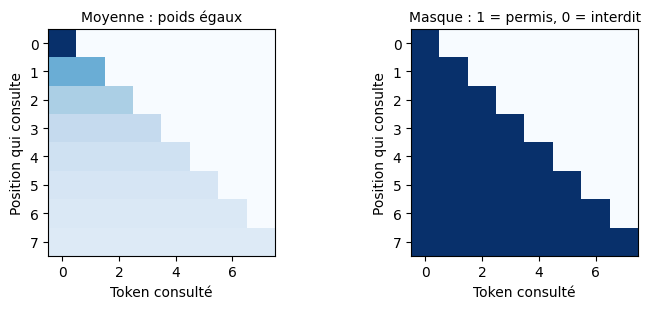

In [ ]:
tril = torch.tril(torch.ones(T, T))
scores_matrix = torch.zeros((T, T))
scores_matrix = scores_matrix.masked_fill(tril == 0, float("-inf"))
weights_softmax = F.softmax(scores_matrix, dim=-1)
print("Mêmes poids :", torch.allclose(weights, weights_softmax))

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.2))
for ax, matrix, title in [(axes[0], weights_softmax, "Moyenne : poids égaux"), (axes[1], tril, "Masque : 1 = permis, 0 = interdit")]:
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Token consulté")
    ax.set_ylabel("Position qui consulte")
plt.tight_layout()
plt.show()

Cette écriture a une interprétation : `scores_matrix` mesure **l’affinité entre deux tokens**. Un score de $-\infty$ veut dire « aucune communication » (le futur). Les zéros veulent dire « aucune préférence », d’où une moyenne.

Mais rien n’oblige ces scores à être nuls. Si un modèle pouvait les **calculer à partir des données**, chaque token pourrait choisir quels tokens passés comptent pour lui. C’est exactement l’auto-attention.

### Étape 4 : requêtes, clés et valeurs

Chaque token produit trois vecteurs, à l’aide de trois couches linéaires apprises :

- **Requête (*query*)** : ce que ce token cherche. Dans « la petite chatte noire dort », le verbe pourrait demander : « qui fait l’action ? »
- **Clé (*key*)** : ce que ce token propose. Le nom pourrait répondre : « je suis un sujet possible. »
- **Valeur (*value*)** : ce que ce token communique à ceux qui s’intéressent à lui.

Le score d’affinité entre deux tokens est le **produit scalaire** de la requête de l’un et de la clé de l’autre. Plus ils s’alignent, plus le poids est grand.

Le schéma suit la cellule de code ci-dessous, ligne par ligne, avec les mêmes noms de variables (`hs` est `head_size`). Regardez surtout les formes : `@` est un produit de matrices, et c’est `(B, T, T)` qui donne un score pour chaque paire de tokens. La mise à l’échelle, en pointillés, viendra à l’étape 5.

![Le calcul d’une tête d’attention, de gauche à droite : x passe par trois couches linéaires qui donnent q, k et v. Le produit de q et de k transposée donne une matrice de scores T par T. Le masque met le futur à moins l’infini et le softmax donne les poids. Le produit des poids et de v donne la sortie.](https://raw.githubusercontent.com/milarobotlearningcourse/data_science/main/demo_5/images/attention_calcul.png)

Sortie : torch.Size([4, 8, 16])


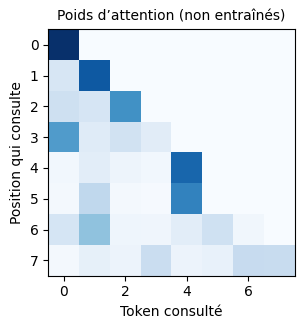

In [ ]:
torch.manual_seed(1337)
B, T, C = 4, 8, 32
x = torch.randn(B, T, C)
head_size = 16

key = nn.Linear(C, head_size, bias=False)
query = nn.Linear(C, head_size, bias=False)
value = nn.Linear(C, head_size, bias=False)

k = key(x)    # (B, T, head_size)
q = query(x)  # (B, T, head_size)

# La communication entre les tokens se passe ici.
affinity = q @ k.transpose(-2, -1)  # (B, T, head_size) @ (B, head_size, T) -> (B, T, T)

tril = torch.tril(torch.ones(T, T))
affinity = affinity.masked_fill(tril == 0, float("-inf"))
attention_weights = F.softmax(affinity, dim=-1)

v = value(x)
out = attention_weights @ v  # (B, T, T) @ (B, T, head_size) -> (B, T, head_size)
print("Sortie :", out.shape)

fig, ax = plt.subplots(figsize=(3.6, 3.2))
ax.imshow(attention_weights[0].detach(), cmap="Blues", vmin=0, vmax=1)
ax.set_title("Poids d’attention (non entraînés)", fontsize=10)
ax.set_xlabel("Token consulté")
ax.set_ylabel("Position qui consulte")
plt.show()

Les poids ne sont plus uniformes : ils dépendent maintenant des données, et ils sont différents pour chaque séquence du batch. Le masque garde sa forme triangulaire. Pour l’instant, ces poids n’ont aucun sens, puisque rien n’est entraîné.

### Étape 5 : la mise à l’échelle

L’article divise les scores par $\sqrt{d_k}$, où $d_k$ est la taille de la tête, d’où le nom d’attention *scaled dot-product*. Pourquoi ? Si `q` et `k` ont une variance de 1, leur produit scalaire a une variance d’environ `head_size` :

In [ ]:
torch.manual_seed(1337)
k = torch.randn(B, T, head_size)
q = torch.randn(B, T, head_size)
raw = q @ k.transpose(-2, -1)
scaled = raw * head_size**-0.5
print(f"Variance de q : {q.var():.2f} | de k : {k.var():.2f}")
print(f"Variance du produit scalaire : {raw.var():.2f}")
print(f"Après division par la racine de head_size : {scaled.var():.2f}")

Variance de q : 1.06 | de k : 1.09
Variance du produit scalaire : 18.44
Après division par la racine de head_size : 1.15


Et c’est un problème, car de grands scores rendent le softmax très « dur » : presque tout le poids va sur un seul token, et chaque token ne consulte plus qu’un seul autre token.

In [ ]:
example = torch.tensor([0.1, -0.2, 0.3, -0.2, 0.5])
for factor in [1, 8]:
    probs = F.softmax(example * factor, dim=-1)
    print(f"softmax(scores × {factor}) :", [round(p, 3) for p in probs.tolist()])

softmax(scores × 1) : [0.192, 0.143, 0.235, 0.143, 0.287]
softmax(scores × 8) : [0.033, 0.003, 0.162, 0.003, 0.8]


Voici donc la formule complète de l’article :

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^T}{\sqrt{d_k}}\right) V$$

### À vous : écrire l’attention

Complétez cette fonction en ajoutant le masque au calcul de la formule. Là où `mask` vaut 0, le score doit devenir $-\infty$. La cellule suivante vérifie votre réponse, entre autres en la comparant à la fonction toute faite de PyTorch.

In [ ]:
def scaled_attention(q, k, v, mask=None):
    # q, k, v : (B, T, head_size), mask : (T, T) ou None
    # Votre code ici : remplacez pass par le calcul, puis renvoyez le résultat.
    pass

In [ ]:
torch.manual_seed(0)
q_test, k_test, v_test = torch.randn(2, 5, 8), torch.randn(2, 5, 8), torch.randn(2, 5, 8)
mask_test = torch.tril(torch.ones(5, 5))
result = scaled_attention(q_test, k_test, v_test, mask_test)

if result is None:
    print("La fonction n'est pas encore complétée.")
else:
    assert result.shape == (2, 5, 8), "Mauvaise forme de sortie."
    assert torch.allclose(result[:, 0], v_test[:, 0]), "La première position ne doit voir qu'elle-même."
    future_changed = v_test.clone()
    future_changed[:, -1] += 100.0
    changed = scaled_attention(q_test, k_test, future_changed, mask_test)
    assert torch.allclose(result[:, :-1], changed[:, :-1]), "Le futur ne doit pas influencer le passé."
    expected = F.scaled_dot_product_attention(q_test, k_test, v_test, attn_mask=mask_test.bool())
    assert torch.allclose(result, expected, atol=1e-5), "Vérifiez la mise à l'échelle."
    print("Bravo ! Votre attention donne le même résultat que celle de PyTorch.")

La fonction n'est pas encore complétée.


<details>
<summary>Réponse de référence — à ouvrir après avoir essayé</summary>

```python
def scaled_attention(q, k, v, mask=None):
    scores = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5
    if mask is not None:
        scores = scores.masked_fill(mask == 0, float("-inf"))
    return F.softmax(scores, dim=-1) @ v
```

Si vous avez essayé cette réponse, réexécutez la cellule de vérification.

</details>

### Une tête d’attention

Nous pouvons maintenant tout réunir dans un module. `tril` n’est pas un paramètre à apprendre : PyTorch appelle cela un *buffer*. L’option `causal` (le masque qui cache le futur) nous permettra de le retirer plus tard.

In [ ]:
class Head(nn.Module):
    def __init__(self, n_embd, head_size, block_size, dropout=0.0, causal=True):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(dropout)
        self.causal = causal

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)    # (B, T, head_size)
        q = self.query(x)  # (B, T, head_size)
        scores = q @ k.transpose(-2, -1) * k.shape[-1] ** -0.5  # (B, T, T)
        if self.causal:
            scores = scores.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        self.last_weights = weights.detach()  # conservés pour les afficher à la section E
        weights = self.dropout(weights)
        v = self.value(x)  # (B, T, head_size)
        return weights @ v  # (B, T, head_size)

### À vous : l’attention connaît-elle l’ordre des mots ?

Créez une tête **sans masque** : `Head(8, 8, block_size=16, causal=False)`. Prenez une entrée `x = torch.randn(1, 6, 8)` et une permutation `perm = torch.randperm(6)`. Comparez ensuite `head(x)[:, perm]` et `head(x[:, perm])` avec `torch.allclose(..., atol=1e-6)`.

Qu’observez-vous ? Qu’est-ce que cela veut dire pour une phrase comme « le chat mange la souris » ?

In [ ]:
# Votre code ici

<details>
<summary>Réponse de référence — à ouvrir après avoir essayé</summary>

```python
torch.manual_seed(0)
head = Head(8, 8, block_size=16, causal=False)
x = torch.randn(1, 6, 8)
perm = torch.randperm(6)
print(torch.allclose(head(x)[:, perm], head(x[:, perm]), atol=1e-6))
```

Les deux résultats sont identiques : mélanger l’entrée mélange la sortie de la même façon, sans rien changer d’autre. L’attention travaille sur un **ensemble** de vecteurs, et elle n’a aucune notion d’ordre. Sans autre information, « le chat mange la souris » et « la souris mange le chat » contiennent les mêmes mots et donneraient donc les mêmes résultats.

C’est pourquoi on ajoute à chaque token un vecteur qui dépend de sa **position**. L’article utilise des sinusoïdes fixes; nous apprendrons ces vecteurs, comme GPT, avec une deuxième table de plongements.

</details>

### Ce qu’il faut retenir sur l’attention

1. **C’est un mécanisme de communication.** Chaque token rassemble de l’information sur les autres, avec des poids qu’il calcule lui-même. Ici, chaque position reçoit de toutes celles qui la précèdent et d’elle-même.
2. **Elle n’a aucune notion de position.** Il faut encoder la position explicitement, comme nous venons de le voir.
3. **Les séquences d’un batch ne se parlent jamais.** Elles sont traitées en parallèle, indépendamment.
4. **Le masque dépend de l’usage.** Il est indispensable pour générer du texte, car le futur est inconnu. Sans objectif de génération, on peut le retirer : nous le ferons pour les images à la section G.
5. **Auto-attention ou attention croisée.** Ici, requêtes, clés et valeurs viennent toutes de `x`, d’où le nom d’auto-attention. Si clés et valeurs venaient d’une autre source (l’encodeur d’un traducteur, par exemple), ce serait de l’attention croisée.

## D. Du mécanisme d’attention au Transformer

Nous allons assembler le modèle une pièce à la fois et mesurer chaque ajout. Pour que la comparaison soit juste, toutes les versions utilisent le même nombre de pas, le même taux d’apprentissage et les mêmes tailles.

Seule la partie centrale change d’une version à l’autre. Nous la passons donc au modèle sous le nom de `body`. Le reste ne bouge plus. Un **plongement** (*embedding*) est un vecteur appris : chaque token en reçoit un, chaque **position** aussi, et on les additionne. Une couche linéaire produit ensuite les logits.

In [ ]:
class TransformerLM(LanguageModel):
    def __init__(self, vocab_size, n_embd, block_size, body):
        super().__init__()
        self.block_size = block_size
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.body = body
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def compute_logits(self, idx):
        T = idx.shape[1]
        tok_emb = self.token_embedding_table(idx)  # (B, T, n_embd)
        pos_emb = self.position_embedding_table(torch.arange(T, device=idx.device))  # (T, n_embd)
        return self.lm_head(self.body(tok_emb + pos_emb))  # (B, T, vocab_size)


# Mêmes réglages pour toutes les versions de cette section.
n_embd, n_head, n_layer, block_size = 64, 4, 6, 32

### Version 1 : une seule tête d’attention

In [ ]:
model_v1 = TransformerLM(vocab_size, n_embd, block_size, body=Head(n_embd, n_embd, block_size))
train(model_v1, block_size, name="Une tête")
print()
sample(model_v1, max_new_tokens=200)

pas     0 | entraînement 4.235 | validation 4.228 |    0 s
pas   375 | entraînement 2.678 | validation 2.679 |    2 s
pas   750 | entraînement 2.472 | validation 2.496 |    3 s
pas  1125 | entraînement 2.393 | validation 2.430 |    5 s
pas  1500 | entraînement 2.373 | validation 2.401 |    7 s


Whe the RAnNocowi, ht son, bth
Y: het bobe ule.
S:
O:
I Med?
ITanss:
Whitharuul he, vet?
F dilas ates wice my.

Thy atut otoup
Yowns, tof is he me mil; dill, bes iree sen cie lat Het drovets, heen me 


### Version 2 : plusieurs têtes en parallèle

Une tête ne regarde qu’une sorte de relation à la fois. L’article en utilise plusieurs, chacune avec ses propres requêtes, clés et valeurs, sur des vecteurs plus petits. On concatène leurs sorties pour revenir à `n_embd`, puis une couche linéaire les mélange.

*Attention multi-têtes* : c’est juste la même opération plusieurs fois, en parallèle. Le schéma utilise nos réglages : 4 têtes et `n_embd = 64`.

![L’attention multi-têtes avec 4 têtes : chaque tête reçoit tout x, de forme B, T, 64, et produit une sortie B, T, 16. On concatène les quatre sorties pour revenir à B, T, 64, puis la couche linéaire proj les mélange.](https://raw.githubusercontent.com/milarobotlearningcourse/data_science/main/demo_5/images/multi_tetes.png)

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout=0.0, causal=True):
        super().__init__()
        head_size = n_embd // n_head
        self.heads = nn.ModuleList(
            [Head(n_embd, head_size, block_size, dropout, causal) for _ in range(n_head)]
        )
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([head(x) for head in self.heads], dim=-1)  # (B, T, n_embd)
        return self.dropout(self.proj(out))


model_v2 = TransformerLM(vocab_size, n_embd, block_size, body=MultiHeadAttention(n_embd, n_head, block_size))
train(model_v2, block_size, name="Plusieurs têtes")
print()
sample(model_v2, max_new_tokens=200)

pas     0 | entraînement 4.152 | validation 4.153 |    0 s
pas   375 | entraînement 2.528 | validation 2.530 |    3 s
pas   750 | entraînement 2.367 | validation 2.381 |    6 s
pas  1125 | entraînement 2.258 | validation 2.304 |    9 s
pas  1500 | entraînement 2.213 | validation 2.250 |   12 s


And they bridcowd,
This and to
Yaitelk ofe hee.
Sagr-3 my calald
My:
Whith fun qurthe. bur diladsaten will my.

Ond acum onoug
Youts
MUTf ing I He mil nowll, aes ireens, hcin lat Heridrov te, and ting


### Version 3 : communiquer, puis réfléchir

Après l’attention, les tokens ont rassemblé de l’information, mais n’ont pas eu le temps de la traiter : la seule opération non linéaire jusqu’ici est le softmax des poids. On ajoute donc un petit réseau appliqué **à chaque position séparément** : le réseau *feed-forward*. Comme dans l’article, sa couche cachée est 4 fois plus large.

L’attention est l’étape de **communication**; le réseau *feed-forward* est l’étape de **calcul**.

In [ ]:
class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


body_v3 = nn.Sequential(MultiHeadAttention(n_embd, n_head, block_size), FeedForward(n_embd))
model_v3 = TransformerLM(vocab_size, n_embd, block_size, body=body_v3)
train(model_v3, block_size, name="+ feed-forward")
print()
sample(model_v3, max_new_tokens=200)

pas     0 | entraînement 4.185 | validation 4.185 |    0 s
pas   375 | entraînement 2.419 | validation 2.420 |    3 s
pas   750 | entraînement 2.253 | validation 2.271 |    6 s
pas  1125 | entraînement 2.125 | validation 2.173 |   10 s
pas  1500 | entraînement 2.054 | validation 2.116 |   13 s


Whin thy bridcowill kis be be madisel bube to take ruand meatied
he ard that usquit tetbar dilascanes wick, you, not to zremme
Yowns, tof it he coom thelill, at mireets, hain latistlid ov the hee the 


### Version 4 : empiler des blocs

Un **bloc** regroupe communication et calcul (rien à voir avec les blocs de texte de `block_size`). En empilant plusieurs blocs, on laisse l’information circuler plusieurs fois. Essayons avec 6 blocs, sans autre précaution.

In [ ]:
class PlainBlock(nn.Module):
    def __init__(self, n_embd, n_head, block_size):
        super().__init__()
        self.sa = MultiHeadAttention(n_embd, n_head, block_size)
        self.ffwd = FeedForward(n_embd)

    def forward(self, x):
        x = self.sa(x)
        x = self.ffwd(x)
        return x


body_v4 = nn.Sequential(*[PlainBlock(n_embd, n_head, block_size) for _ in range(n_layer)])
model_v4 = TransformerLM(vocab_size, n_embd, block_size, body=body_v4)
train(model_v4, block_size, name="6 blocs simples")
print()
sample(model_v4, max_new_tokens=200)

pas     0 | entraînement 4.153 | validation 4.153 |    1 s
pas   375 | entraînement 3.308 | validation 3.358 |   15 s
pas   750 | entraînement 3.263 | validation 3.303 |   28 s
pas  1125 | entraînement 3.146 | validation 3.163 |   41 s
pas  1500 | entraînement 3.127 | validation 3.151 |   55 s


sllnt ikRtridcowd,eh O ln,e te
baiPeok Baeou etaStgOta mt dalahauhs:ar hthheuuhqhr hv.tb F dtlahoaoe awccr m W nfnsdaYu  otouh
Yowts
mtof iaIh bot miW ndilit,aeg ireeesenhcie latismtidrov ts, ate
Wk  


En 1 500 pas, la perte descend seulement autour de 3, bien pire qu’avec un seul bloc, et le texte ne ressemble plus à de l’anglais. Ce n’est guère mieux qu’un modèle qui connaîtrait seulement la fréquence de chaque lettre (environ 3,31). Avec plus de paramètres, le modèle a donc appris **moins**. Le problème n’est pas qu’il manque de capacité : il est devenu **trop difficile à entraîner**, car le gradient et l’information doivent traverser une longue chaîne de transformations et se dégradent en route. Deux astuces, toutes deux dans l’article, règlent cela.

### Version 5 : les connexions résiduelles

La première astuce vient de l’article *ResNet* (2015). Au lieu de remplacer `x` par `f(x)`, on l’additionne : $x \rightarrow x + f(x)$.

Le gradient dispose ainsi d’un chemin direct de la sortie jusqu’à l’entrée, comme une autoroute qui traverse tous les blocs. Et chaque bloc n’a plus à reconstruire toute l’information : il lui suffit d’apprendre une correction à apporter à `x`.

In [ ]:
class ResidualBlock(PlainBlock):
    def forward(self, x):
        x = x + self.sa(x)
        x = x + self.ffwd(x)
        return x


body_v5 = nn.Sequential(*[ResidualBlock(n_embd, n_head, block_size) for _ in range(n_layer)])
model_v5 = TransformerLM(vocab_size, n_embd, block_size, body=body_v5)
train(model_v5, block_size, name="+ résiduelles")
print()
sample(model_v5, max_new_tokens=200)

pas     0 | entraînement 4.676 | validation 4.692 |    1 s
pas   375 | entraînement 2.168 | validation 2.192 |   14 s
pas   750 | entraînement 1.954 | validation 2.044 |   28 s
pas  1125 | entraînement 1.826 | validation 1.981 |   42 s
pas  1500 | entraînement 1.748 | validation 1.910 |   56 s



ANTIO:
Renidly, and is not this: well of Au enamign-damble?
That such haphe usquech bures dilascates wick my.

HENRY POLING RIVI:
But of is he coverly, whit,
Which ensengmin; at Hered overs, and Wall


### Version 6 : la normalisation de couche

La deuxième astuce consiste à garder les activations à une échelle stable. La **normalisation de couche** (*LayerNorm*) ramène chaque vecteur à une moyenne de 0 et à un écart type de 1, puis apprend une échelle et un décalage. Rien de magique, comme le montre cette vérification :

In [ ]:
torch.manual_seed(0)
x = torch.randn(2, 3, 4)
layer_norm = nn.LayerNorm(4, elementwise_affine=False)  # sans les paramètres appris
by_hand = (x - x.mean(dim=-1, keepdim=True)) / x.std(dim=-1, unbiased=False, keepdim=True)
print("Même résultat qu'à la main :", torch.allclose(layer_norm(x), by_hand, atol=1e-3))

Même résultat qu'à la main : True


Nous appliquons la normalisation **avant** chaque sous-couche, comme GPT-2 et les modèles récents. L’article la place après : c’est l’une des rares différences avec le schéma d’origine.

Nous ajoutons aussi le **dropout** : pendant l’entraînement, on met à zéro des valeurs au hasard, ce qui empêche le réseau de trop dépendre d’un petit nombre de connexions. C’est une protection contre le surapprentissage. Il se désactive à l’évaluation, d’où le `model.eval()` vu plus haut. Il ne sert à rien tant que le modèle est petit : nous l’activerons à la section E.

Voici le bloc final. L’option `causal` est transmise jusqu’aux têtes d’attention.

In [ ]:
class Block(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout=0.0, causal=True):
        super().__init__()
        self.sa = MultiHeadAttention(n_embd, n_head, block_size, dropout, causal)
        self.ffwd = FeedForward(n_embd, dropout)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))    # communication
        x = x + self.ffwd(self.ln2(x))  # calcul
        return x


body_v6 = nn.Sequential(
    *[Block(n_embd, n_head, block_size) for _ in range(n_layer)],
    nn.LayerNorm(n_embd),  # une dernière normalisation avant les logits
)
model_v6 = TransformerLM(vocab_size, n_embd, block_size, body=body_v6)
train(model_v6, block_size, name="+ LayerNorm")
print()
sample(model_v6, max_new_tokens=200)

pas     0 | entraînement 4.403 | validation 4.387 |    1 s
pas   375 | entraînement 2.240 | validation 2.248 |   15 s
pas   750 | entraînement 2.023 | validation 2.089 |   29 s
pas  1125 | entraînement 1.855 | validation 1.973 |   43 s
pas  1500 | entraînement 1.773 | validation 1.911 |   58 s



ANTIO:
Rencecowice, is by blorged, that you eyarth thest:
Shaldess art that usqure totly, dilth ane are rumpan,
Dlance zongun
You, proof isterble milend!
Who eselfeens, hand latistlinker the hee
Will


### Le bilan

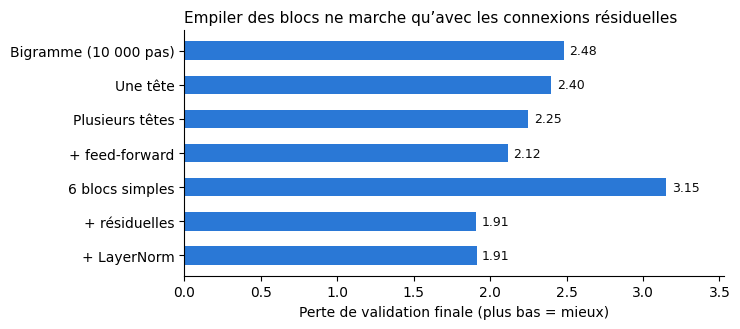

In [ ]:
names = list(scores)
values = [scores[name] for name in names]

fig, ax = plt.subplots(figsize=(7.5, 3.4))
bars = ax.barh(names, values, height=0.55, color="#2a78d6")
ax.bar_label(bars, labels=[f"{value:.2f}" for value in values], padding=4, fontsize=9, color="#0b0b0b")
ax.invert_yaxis()
ax.set_xlim(0, max(values) * 1.12)
ax.set_xlabel("Perte de validation finale (plus bas = mieux)")
ax.set_title("Empiler des blocs ne marche qu’avec les connexions résiduelles", fontsize=11, loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Lisez le graphique de haut en bas. Regarder tout le contexte plutôt qu’un seul caractère, multiplier les têtes et ajouter le calcul font chacun baisser la perte. Empiler les blocs sans précaution annule tout. Avec les connexions résiduelles, la profondeur devient enfin payante, et c’est le meilleur résultat jusqu’ici.

À cette petite échelle, la normalisation de couche ne change presque rien à la perte finale. Nous la gardons quand même : c’est sur des réseaux plus grands et plus profonds qu’elle devient vraiment utile. Ne surinterprétez pas non plus les petits écarts : il s’agit d’une seule exécution, et un autre tirage aléatoire ferait bouger la deuxième décimale.

## E. Notre GPT

Réunissons tout dans un seul modèle, très proche du fichier [`gpt.py`](https://github.com/karpathy/ng-video-lecture/blob/master/gpt.py) de Karpathy. Le contexte devient plus long, le modèle plus grand, et le dropout entre en jeu.

Nous ajoutons une dernière chose : une meilleure **initialisation**. De petits poids au départ donnent des logits presque uniformes, donc une perte initiale proche de $\ln(V)$. C’est le calcul de votre premier exercice.

In [ ]:
class GPTLanguageModel(LanguageModel):
    def __init__(self, vocab_size, block_size, n_embd, n_head, n_layer, dropout=0.0, causal=True):
        super().__init__()
        self.block_size = block_size
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(
            *[Block(n_embd, n_head, block_size, dropout, causal) for _ in range(n_layer)]
        )
        self.ln_f = nn.LayerNorm(n_embd)  # dernière normalisation
        self.lm_head = nn.Linear(n_embd, vocab_size)
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
        if isinstance(module, nn.Linear) and module.bias is not None:
            nn.init.zeros_(module.bias)

    def compute_logits(self, idx):
        T = idx.shape[1]
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(torch.arange(T, device=idx.device))
        x = self.blocks(tok_emb + pos_emb)
        return self.lm_head(self.ln_f(x))

La **configuration pour la classe** s’entraîne en quelques minutes sur un CPU. La **configuration complète** est celle de Karpathy : elle demande un GPU, par exemple sur Colab. Pour l’essayer plus tard, remplacez `CLASS_CONFIG` par `FULL_CONFIG` ci-dessous.

**Les résultats enregistrés dans ce notebook viennent de la configuration complète** (environ 43 minutes sur le GPU T4 de Colab). Avec `CLASS_CONFIG`, vous obtiendrez environ 354 000 paramètres, une perte de validation autour de 1,7 et un texte moins abouti.

In [ ]:
CLASS_CONFIG = dict(block_size=64, n_embd=96, n_head=4, n_layer=3, dropout=0.1,
                    steps=2000, batch_size=64, learning_rate=1e-3)
FULL_CONFIG = dict(block_size=256, n_embd=384, n_head=6, n_layer=6, dropout=0.2,
                   steps=5000, batch_size=64, learning_rate=3e-4)

config = CLASS_CONFIG  # Avec un GPU : config = FULL_CONFIG

model_args = {name: config[name] for name in ["block_size", "n_embd", "n_head", "n_layer", "dropout"]}
train_args = {name: config[name] for name in ["block_size", "steps", "batch_size", "learning_rate"]}

torch.manual_seed(1337)
model = GPTLanguageModel(vocab_size, **model_args)
print(f"{spaced(count_parameters(model))} paramètres")
print(f"Perte uniforme attendue : {math.log(vocab_size):.3f}")

10 788 929 paramètres
Perte uniforme attendue : 4.174


In [ ]:
history = train(model, name="GPT final", n_reports=9, **train_args)

pas     0 | entraînement 4.222 | validation 4.230 |   18 s
pas   625 | entraînement 1.601 | validation 1.775 |  343 s
pas  1250 | entraînement 1.326 | validation 1.561 |  665 s
pas  1875 | entraînement 1.211 | validation 1.517 |  986 s
pas  2500 | entraînement 1.129 | validation 1.511 | 1305 s
pas  3125 | entraînement 1.056 | validation 1.510 | 1617 s
pas  3750 | entraînement 0.990 | validation 1.521 | 1929 s
pas  4375 | entraînement 0.918 | validation 1.534 | 2241 s
pas  5000 | entraînement 0.858 | validation 1.576 | 2553 s


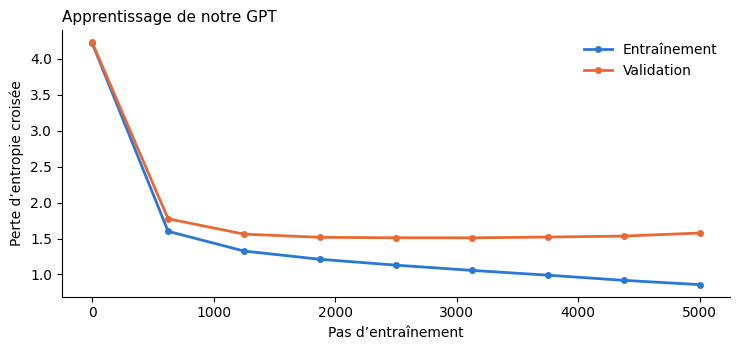

Écart final validation - entraînement : 0.718


In [ ]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(history["step"], history["train"], color="#2a78d6", linewidth=2, marker="o", markersize=4, label="Entraînement")
ax.plot(history["step"], history["val"], color="#eb6834", linewidth=2, marker="o", markersize=4, label="Validation")
ax.set_xlabel("Pas d’entraînement")
ax.set_ylabel("Perte d’entropie croisée")
ax.set_title("Apprentissage de notre GPT", fontsize=11, loc="left")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(f"Écart final validation - entraînement : {history['val'][-1] - history['train'][-1]:.3f}")

Une validation qui s’éloigne de l’entraînement signale d’habitude un début de surapprentissage : le modèle retient des particularités du corpus. Ici, une partie de l’écart vient aussi de la validation elle-même, faite surtout de pièces que le modèle a peu ou pas vues.

Générons maintenant du texte, en partant d’un personnage de *Roméo et Juliette*.

In [ ]:
torch.manual_seed(1337)
sample(model, prompt="ROMEO:\n", max_new_tokens=700)

ROMEO:
And therefore were he wont to-morrow,
To see that graves me little bar happiness.
Then be determine, away! my father, by yonder:
If ever I did but mild with caes it eye,
I'll lamentations to and wife and perform.

BALTHASAR:
Sir Juliet, what stuff air shall be long.
I cannot blame your mistress to keep Willow her:
I brieve thee, and Tranio, now proclaim for the king.

BISHOP OF ELY:
Look, there is no staff, but never of true-bed;
But yet saw her brother's love, hence and add
His grave from her conquest our marriage.

HASTINGS:

GLOUCESTER:
Son, good Sir JOHN OF GANT:
Be patient turn on, with childish men
Deck our tentings of all the sorrow's wife,
To take dissemble of trumpetimes;
Or in that


Le texte ne veut rien dire, mais regardez ce que le modèle a appris seul, à partir de simples caractères : des noms de personnages en majuscules suivis de deux-points, des répliques, des vers courts, de la ponctuation et beaucoup de vrais mots. Il mélange des personnages de plusieurs pièces, car il ne comprend rien : **il prédit seulement le prochain caractère probable.**

### Que regarde le modèle ?

Affichons les poids d’attention du dernier bloc sur une vraie phrase, une carte par tête. Chaque ligne est une position; chaque colonne, le caractère qu’elle consulte.

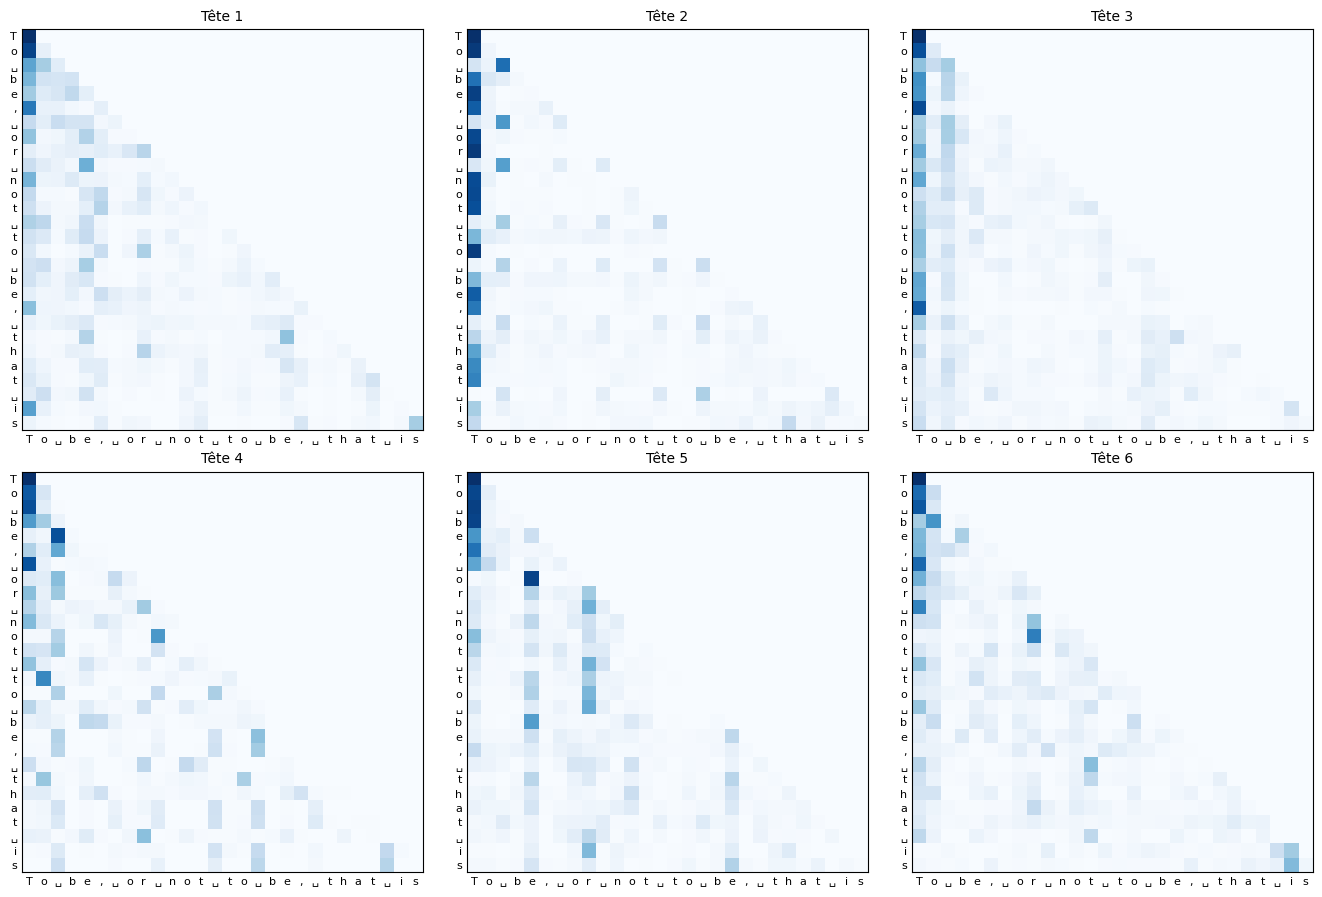

In [ ]:
phrase = "To be, or not to be, that is"
idx = torch.tensor([encode(phrase)], device=device)
model.eval()
with torch.no_grad():
    model(idx)
model.train()

heads = model.blocks[-1].sa.heads
n_columns = math.ceil(len(heads) / 2)
fig, axes = plt.subplots(2, n_columns, figsize=(4.5 * n_columns, 9), sharex=True, sharey=True)
labels = [c if c != " " else "␣" for c in phrase]
for i, (ax, head) in enumerate(zip(axes.flat, heads)):
    ax.imshow(head.last_weights[0].cpu(), cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"Tête {i + 1}", fontsize=10)
    ax.set_xticks(range(len(labels)), labels, fontsize=8)
    ax.set_yticks(range(len(labels)), labels, fontsize=8)
    ax.tick_params(labelbottom=True, labelleft=True, length=0)
plt.tight_layout()
plt.show()

Chaque tête a son propre motif. Certaines colonnes ressortent : un même caractère est consulté par plusieurs positions. Ne cherchez pas de grammaire ici. Ce petit modèle travaille sur des caractères et ses têtes n’ont pas de rôle aussi net que dans l’exemple de la vidéo : c’est l’entraînement, et non nous, qui décide de ce qu’elles regardent.

### À vous : et si on retirait le masque ?

Créez un modèle `GPTLanguageModel(vocab_size, causal=False, **model_args)` et entraînez-le pendant 300 pas (`train(tricheur, block_size=..., steps=300, ...)`). Observez sa perte de validation, puis générez du texte.

La perte devrait être excellente, et le texte, catastrophique. **Pourquoi ?** Pensez à ce que voit le modèle à l’entraînement, puis à ce qu’il voit en génération.

In [ ]:
# Votre code ici

<details>
<summary>Réponse de référence — à ouvrir après avoir essayé</summary>

```python
tricheur = GPTLanguageModel(vocab_size, causal=False, **model_args)
train(tricheur, block_size=config["block_size"], steps=300, batch_size=config["batch_size"],
      learning_rate=config["learning_rate"])
print()
sample(tricheur, prompt="ROMEO:\n", max_new_tokens=200)
```

Les cibles sont simplement l’entrée décalée d’un cran. Sans masque, chaque position voit donc sa propre réponse dans le reste de la séquence : il suffit de copier le token suivant. Seule la dernière position doit vraiment prédire quelque chose. En génération, on utilise justement cette dernière position, celle que le modèle n’a presque pas appris à traiter.

C’est une **fuite de données**, comme celles de la démo 4 : la perte de validation semble excellente parce que l’entrée contient la réponse, pas parce que le modèle est bon.

</details>

### À vous : la température

`generate` tire les caractères selon les probabilités du softmax. On peut contrôler ce tirage en divisant les logits par une **température** $\tau$ juste avant le softmax.

Écrivez `generate_with_temperature(model, idx, max_new_tokens, temperature)` en vous inspirant de `LanguageModel.generate`. Comparez les textes pour $\tau = 0{,}3$, $1$ et $2$. Quel lien faites-vous avec la mise à l’échelle de la section C ?

In [ ]:
# Votre code ici

<details>
<summary>Réponse de référence — à ouvrir après avoir essayé</summary>

```python
@torch.no_grad()
def generate_with_temperature(model, idx, max_new_tokens, temperature=1.0):
    model.eval()
    for _ in range(max_new_tokens):
        logits, _ = model(idx[:, -model.block_size :])
        probs = F.softmax(logits[:, -1, :] / temperature, dim=-1)
        idx_next = torch.multinomial(probs, num_samples=1)
        idx = torch.cat((idx, idx_next), dim=1)
    model.train()
    return idx


start = torch.tensor([encode("ROMEO:\n")], device=device)
for temperature in [0.3, 1.0, 2.0]:
    print(f"--- température {temperature} ---")
    print(decode(generate_with_temperature(model, start, 200, temperature)[0].tolist()))
```

Une température basse amplifie les écarts entre les logits : le softmax devient dur, presque un maximum, et le modèle répète ses suites préférées. Une température élevée aplatit la distribution et le texte devient du bruit. C’est le même phénomène que dans l’étape 5 de la section C, où de grands scores concentraient l’attention sur un seul token.

</details>

### Et les grands modèles ?

Le code ne change presque pas d’un modèle à l’autre : les nombres, si.

| Modèle | Paramètres (environ) |
|---|---|
| Notre GPT, configuration pour la classe | 354 000 |
| Notre GPT, configuration complète | 10,8 millions |
| GPT-2, la plus grande version (2019) | 1,5 milliard |
| GPT-3 (2020) | 175 milliards |

Le texte et les courbes enregistrés plus haut viennent de la configuration complète : voilà ce que donne un modèle de 10,8 millions de paramètres.

## F. Retour à l’article, et vers ChatGPT

Voici ce qui sépare notre modèle de celui d’*Attention Is All You Need*.

| | Article (2017) | Notre GPT |
|---|---|---|
| Tâche | Traduire | Générer du texte |
| Architecture | Encodeur et décodeur | Décodeur seulement |
| Attention croisée | Oui, le décodeur consulte l’encodeur | Non, il n’y a rien à consulter |
| Masque causal | Dans le décodeur | Oui |
| Positions | Sinusoïdes fixes | Plongements appris |
| Normalisation | Après chaque sous-couche | Avant chaque sous-couche |
| Tokens | Morceaux de mots | Caractères |
| Taille | 6 + 6 blocs, 8 têtes, dimension 512 | Voir la section E |
| Optimiseur | Adam avec un taux qui monte, puis décroît | AdamW avec un taux constant |

**L’attention croisée** n’est pas loin de ce que nous avons écrit. Dans `Head`, requêtes, clés et valeurs viennent de `x`. Pour une attention croisée, on calcule les requêtes à partir du texte que le décodeur est en train d’écrire, et les clés et valeurs à partir de la sortie de l’encodeur, sans masque causal.

**Et ChatGPT ?** Notre modèle s’arrête au *pré-entraînement* : il continue un texte, il ne répond pas à des questions. Posez-lui une question et il inventera probablement une autre question. ChatGPT passe par deux grandes étapes :

1. **Le pré-entraînement.** Le même principe que le nôtre, mais avec des morceaux de mots, des centaines de milliers de fois plus de paramètres et une grande partie du Web comme corpus.
2. **L’alignement.** On réentraîne ensuite le modèle à partir d’exemples de bonnes réponses, de jugements humains sur ses réponses, et d’autres techniques, pour qu’il se comporte comme un assistant plutôt que comme un document qui se poursuit.

## G. Et pour les images ?

Rien dans `Block` ne parle de texte : un bloc reçoit des vecteurs et leur permet de communiquer. Le **Vision Transformer** ([ViT](https://arxiv.org/abs/2010.11929), 2020) en profite. Trois changements seulement :

1. **Les *tokens* sont des morceaux d’image.** On découpe l’image en petits carrés (*patches*), et chacun passe par une couche linéaire au lieu d’une table de plongements.
2. **On retire le masque.** Il n’y a pas de futur à cacher dans une image : tous les patches peuvent se consulter. Notre option `causal=False` s’en occupe.
3. **On ajoute un token `[CLS]`.** Ce vecteur appris rejoint la séquence et récolte de l’information sur les patches. Sa sortie finale sert à classifier l’image.

![Comparaison de notre GPT et d’un Vision Transformer, de bas en haut. Ce qui change : l’entrée, nn.Embedding remplacé par nn.Linear, l’ajout du token CLS, l’option causal et la sortie. Ce qui ne change pas : les positions apprises et la classe Block.](https://raw.githubusercontent.com/milarobotlearningcourse/data_science/main/demo_5/images/gpt_vs_vit.png)

Essayons sur les chiffres manuscrits de la démo 4 : des images de 8×8 pixels, que nous découpons en patches de 2×2.

Image : torch.Size([1, 8, 8]) -> séquence de patches : torch.Size([1, 16, 4])


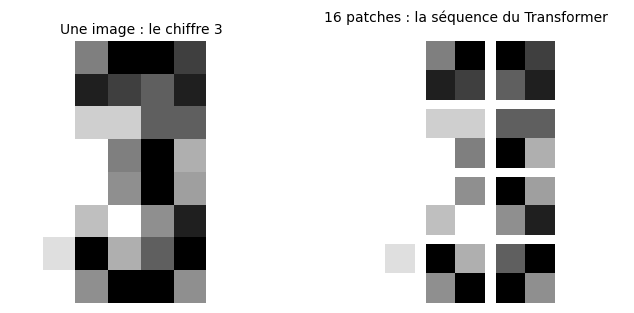

In [ ]:
digits_images, digits_labels = load_digits(return_X_y=True)
images = torch.tensor(digits_images / 16.0, dtype=torch.float32).view(-1, 8, 8)
labels = torch.tensor(digits_labels)
X_train, X_val, y_train, y_val = train_test_split(images, labels, test_size=0.2, random_state=0, stratify=labels)

patch_size = 2
n_patches = (8 // patch_size) ** 2


def to_patches(images, patch_size):
    patches = images.unfold(1, patch_size, patch_size).unfold(2, patch_size, patch_size)  # (B, 4, 4, 2, 2)
    return patches.reshape(len(images), -1, patch_size * patch_size)  # (B, 16, 4)


patches = to_patches(X_train[:1], patch_size)
print("Image :", X_train[:1].shape, "-> séquence de patches :", patches.shape)

fig = plt.figure(figsize=(8, 3.4))
grid = fig.add_gridspec(4, 9, wspace=0.15, hspace=0.15)
main = fig.add_subplot(grid[:, :4])
main.imshow(X_train[0], cmap="gray_r", vmin=0, vmax=1)
main.set_title(f"Une image : le chiffre {y_train[0].item()}", fontsize=10)
main.axis("off")
for i in range(n_patches):
    ax = fig.add_subplot(grid[i // 4, 5 + i % 4])
    ax.imshow(patches[0, i].view(2, 2), cmap="gray_r", vmin=0, vmax=1)
    ax.axis("off")
fig.text(0.70, 0.94, "16 patches : la séquence du Transformer", ha="center", fontsize=10)
plt.show()

In [ ]:
class VisionTransformer(nn.Module):
    def __init__(self, n_patches, patch_dim, n_classes, n_embd=64, n_head=4, n_layer=3):
        super().__init__()
        self.patch_embedding = nn.Linear(patch_dim, n_embd)                  # remplace la table de plongements
        self.cls_token = nn.Parameter(torch.zeros(1, 1, n_embd))             # le token [CLS]
        self.position_embedding = nn.Parameter(torch.randn(1, n_patches + 1, n_embd) * 0.02)
        self.blocks = nn.Sequential(
            *[Block(n_embd, n_head, block_size=n_patches + 1, causal=False) for _ in range(n_layer)]  # sans masque
        )
        self.ln_f = nn.LayerNorm(n_embd)
        self.classifier = nn.Linear(n_embd, n_classes)

    def forward(self, patches):
        tokens = self.patch_embedding(patches)  # (B, n_patches, n_embd)
        cls = self.cls_token.expand(len(patches), -1, -1)
        x = torch.cat([cls, tokens], dim=1) + self.position_embedding  # (B, n_patches + 1, n_embd)
        x = self.ln_f(self.blocks(x))
        return self.classifier(x[:, 0])  # seule la sortie de [CLS] sert à classifier


torch.manual_seed(1337)
vit = VisionTransformer(n_patches, patch_size * patch_size, n_classes=10).to(device)
optimizer = torch.optim.AdamW(vit.parameters(), lr=1e-3)
train_patches = to_patches(X_train, patch_size).to(device)
val_patches = to_patches(X_val, patch_size).to(device)
y_train_device, y_val_device = y_train.to(device), y_val.to(device)

print(f"{spaced(count_parameters(vit))} paramètres")
start = time.time()
for epoch in range(1, 41):
    for batch in torch.randperm(len(train_patches)).split(64):
        loss = F.cross_entropy(vit(train_patches[batch]), y_train_device[batch])
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
    if epoch % 10 == 0:
        vit.eval()
        with torch.no_grad():
            accuracy = (vit(val_patches).argmax(dim=1) == y_val_device).float().mean().item()
        vit.train()
        print(f"époque {epoch:2d} | exactitude en validation {accuracy:.1%} | {time.time() - start:3.0f} s")

151 626 paramètres
époque 10 | exactitude en validation 91.4% |   4 s
époque 20 | exactitude en validation 96.4% |   7 s
époque 30 | exactitude en validation 96.1% |  11 s
époque 40 | exactitude en validation 96.1% |  14 s


Le même `Block` qui écrivait du Shakespeare reconnaît maintenant des chiffres. Sur de vraies photos, le ViT d’origine utilise des patches de 16×16 pixels, d’où le titre de son article : *An Image is Worth 16x16 Words*.

## À retenir

- Un modèle de langue **prédit le prochain token**. Générer, c’est répéter cette prédiction et tirer au hasard.
- L’**attention** est une moyenne pondérée des valeurs, dont les poids sont calculés à partir des données : requêtes × clés, mise à l’échelle, masque, softmax.
- L’attention ne connaît pas l’ordre : il faut ajouter des **positions**.
- Un bloc alterne **communication** (attention multi-têtes) et **calcul** (réseau *feed-forward*).
- Les **connexions résiduelles** et la **normalisation de couche** rendent les réseaux profonds entraînables; le **dropout** limite le surapprentissage.
- Un GPT est le **décodeur** du Transformer de 2017, sans attention croisée.

## Pour aller plus loin

- 3Blue1Brown : [chapitre 5](https://www.youtube.com/watch?v=wjZofJX0v4M) et [chapitre 6](https://www.youtube.com/watch?v=eMlx5fFNoYc), à revoir après ce notebook.
- Andrej Karpathy : [la vidéo complète](https://www.youtube.com/watch?v=kCc8FmEb1nY), son [code](https://github.com/karpathy/ng-video-lecture) et [nanoGPT](https://github.com/karpathy/nanoGPT), une version plus complète capable de reproduire GPT-2.
- L’article d’origine : [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762).
- [*The Illustrated Transformer*](https://jalammar.github.io/illustrated-transformer/), de Jay Alammar, pour l’architecture encodeur-décodeur complète.

Le code de ce notebook est adapté de [`ng-video-lecture`](https://github.com/karpathy/ng-video-lecture), d’Andrej Karpathy, publié sous licence MIT.